# Bank Marketing Subscription Prediction


# 1) Data Loading and Business Understanding

## Task 1.1 Load dataset

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

RANDOM_STATE = 42

df = pd.read_csv("bank-full.csv", sep=";")
df.head()


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [2]:
print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")
print(f"Target column: {df.columns[-1]}")
print(f"Features before leakage review: {df.shape[1] - 1}")


Rows: 45,211
Columns: 17
Target column: y
Features before leakage review: 16


## Task 1.2 Understand the target and business problem

In [3]:
target_counts = df["y"].value_counts().reindex(["no", "yes"], fill_value=0)
target_percent = df["y"].value_counts(normalize=True).reindex(["no", "yes"], fill_value=0) * 100

target_summary = pd.DataFrame({
    "Count": target_counts,
    "Percent": target_percent.round(2)
})
target_summary


,Count,Percent
y,,
no,39922,88.3
yes,5289,11.7


The target is whether a contacted client subscribed to a term deposit. A campaign team can use a model to prioritize clients who are more likely to subscribe.

The classes are imbalanced, so accuracy alone can be misleading: a model that predicts “no” for everyone can still look accurate. We will pay close attention to **recall**, **precision**, **F1**, **ROC-AUC**, and **PR-AUC** for the positive “yes” class.

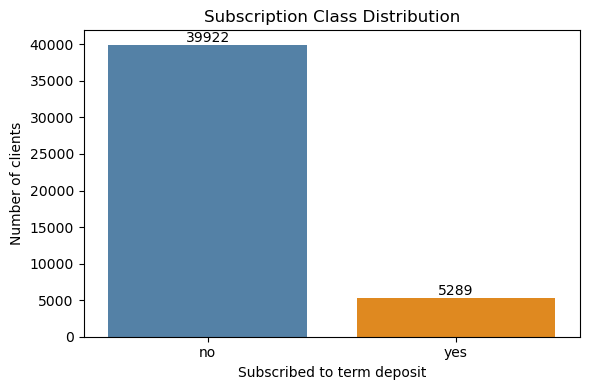

In [4]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=df, x="y", order=["no", "yes"], hue="y", legend=False, ax=ax, palette=["steelblue", "darkorange"])
ax.set_title("Subscription Class Distribution")
ax.set_xlabel("Subscribed to term deposit")
ax.set_ylabel("Number of clients")
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f")
plt.tight_layout()
plt.show()


The count plot makes the class imbalance visible. Most clients did not subscribe, so later evaluation must consider how well each model finds the smaller “yes” group.

# 2) Data Quality and Comprehensive EDA

## Task 2.1 Inspect data types, missing values, duplicates, and ranges

In [5]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        45211 non-null  int64
 1   job        45211 non-null  str  
 2   marital    45211 non-null  str  
 3   education  45211 non-null  str  
 4   default    45211 non-null  str  
 5   balance    45211 non-null  int64
 6   housing    45211 non-null  str  
 7   loan       45211 non-null  str  
 8   contact    45211 non-null  str  
 9   day        45211 non-null  int64
 10  month      45211 non-null  str  
 11  duration   45211 non-null  int64
 12  campaign   45211 non-null  int64
 13  pdays      45211 non-null  int64
 14  previous   45211 non-null  int64
 15  poutcome   45211 non-null  str  
 16  y          45211 non-null  str  
dtypes: int64(7), str(10)
memory usage: 5.9 MB


In [6]:
quality_summary = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2),
    "unique_values": df.nunique()
})
quality_summary


,dtype,missing_count,missing_percent,unique_values
age,int64,0,0.0,77
job,str,0,0.0,12
marital,str,0,0.0,3
education,str,0,0.0,4
default,str,0,0.0,2
balance,int64,0,0.0,7168
housing,str,0,0.0,2
loan,str,0,0.0,2
contact,str,0,0.0,3
day,int64,0,0.0,31


The quality table checks whether columns have missing values and whether fields have the expected number of distinct values. The source dataset represents unknown categories with the text value “unknown”; this is not the same as a missing value and will remain an explicit category.

In [7]:
print(f"Exact duplicate rows: {df.duplicated().sum():,}")
print("Numeric summary:")
display(df.describe().T.round(2))
print("Categorical summary:")
display(df.select_dtypes(exclude=np.number).describe().T)


Exact duplicate rows: 0
Numeric summary:


,count,mean,std,min,25%,50%,75%,max
age,45211.0,40.94,10.62,18.0,33.0,39.0,48.0,95.0
balance,45211.0,1362.27,3044.77,-8019.0,72.0,448.0,1428.0,102127.0
day,45211.0,15.81,8.32,1.0,8.0,16.0,21.0,31.0
duration,45211.0,258.16,257.53,0.0,103.0,180.0,319.0,4918.0
campaign,45211.0,2.76,3.10,1.0,1.0,2.0,3.0,63.0
pdays,45211.0,40.20,100.13,-1.0,-1.0,-1.0,-1.0,871.0
previous,45211.0,0.58,2.30,0.0,0.0,0.0,0.0,275.0


Categorical summary:


,count,unique,top,freq
job,45211,12,blue-collar,9732
marital,45211,3,married,27214
education,45211,4,secondary,23202
default,45211,2,no,44396
housing,45211,2,yes,25130
loan,45211,2,no,37967
contact,45211,3,cellular,29285
month,45211,12,may,13766
poutcome,45211,4,unknown,36959
y,45211,2,no,39922


This dataset has no missing values and contains 45,211 client records with 16 input columns and one target. We keep the source values intact during EDA so later plots describe the original dataset.

The columns pdays and previous describe earlier campaign contact. A pdays value of -1 is a dataset code for “not previously contacted,” not a literal negative number of days. We will create an explicit indicator for that meaning during feature preparation.

## Task 2.2 Explore numerical features

In [8]:
target_numeric = df["y"].map({"no": 0, "yes": 1})
numeric_features_all = df.select_dtypes(include=np.number).columns.tolist()

numeric_summary = df[numeric_features_all].describe().T
numeric_summary["IQR"] = numeric_summary["75%"] - numeric_summary["25%"]
numeric_summary["skew"] = df[numeric_features_all].skew()
numeric_summary.round(2)


,count,mean,std,min,25%,50%,75%,max,IQR,skew
age,45211.0,40.94,10.62,18.0,33.0,39.0,48.0,95.0,15.0,0.68
balance,45211.0,1362.27,3044.77,-8019.0,72.0,448.0,1428.0,102127.0,1356.0,8.36
day,45211.0,15.81,8.32,1.0,8.0,16.0,21.0,31.0,13.0,0.09
duration,45211.0,258.16,257.53,0.0,103.0,180.0,319.0,4918.0,216.0,3.14
campaign,45211.0,2.76,3.10,1.0,1.0,2.0,3.0,63.0,2.0,4.90
pdays,45211.0,40.20,100.13,-1.0,-1.0,-1.0,-1.0,871.0,0.0,2.62
previous,45211.0,0.58,2.30,0.0,0.0,0.0,0.0,275.0,0.0,41.85


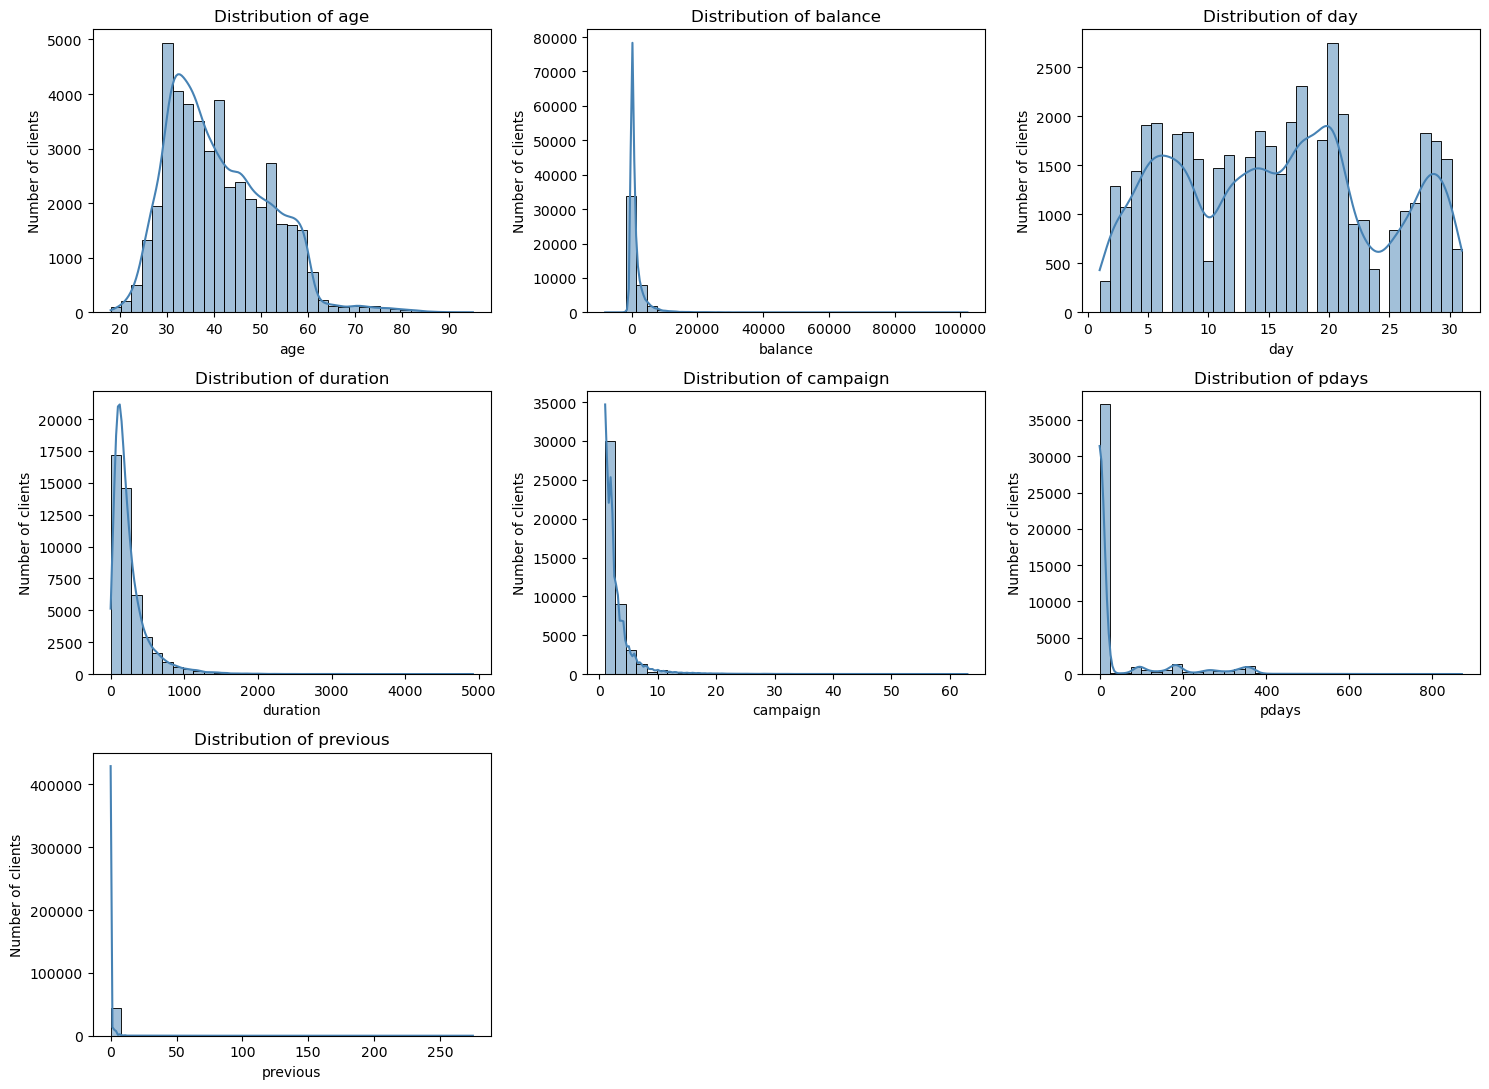

In [9]:
fig, axes = plt.subplots(3, 3, figsize=(15, 11))
for ax, col in zip(axes.flat, numeric_features_all):
    sns.histplot(data=df, x=col, bins=35, kde=True, ax=ax, color="steelblue")
    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Number of clients")
for ax in axes.flat[len(numeric_features_all):]:
    ax.axis("off")
plt.tight_layout()
plt.show()


These histograms show scale, skew, and unusual values. Campaign-related count variables are often right-skewed, so a small number of clients may have many contacts or a large account balance. We inspect these patterns before choosing preprocessing.

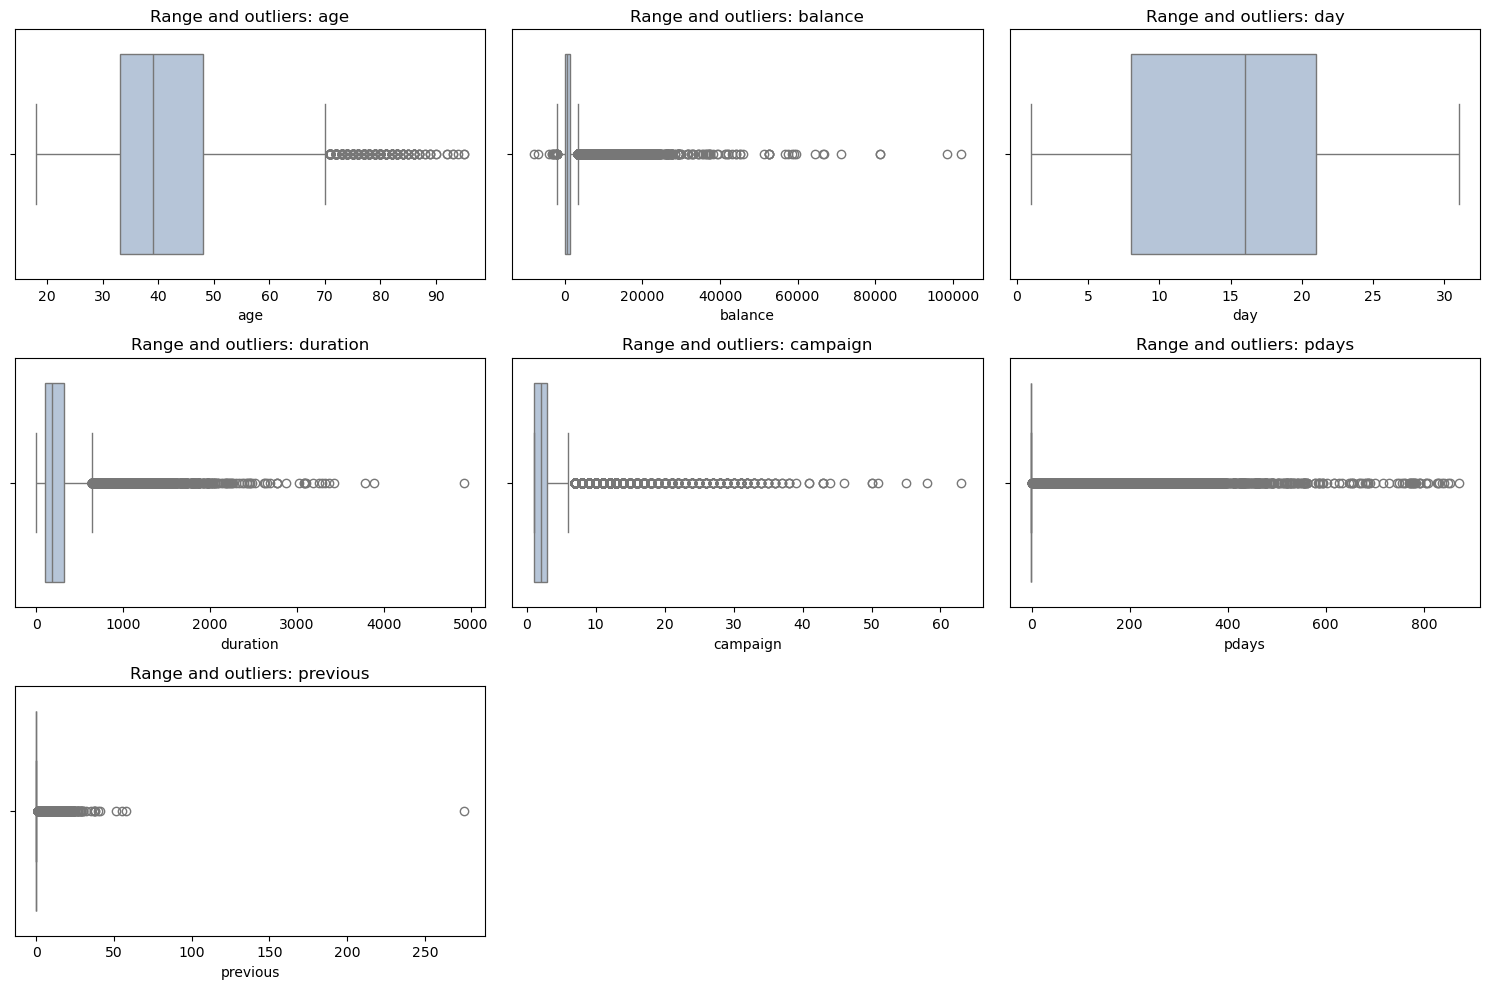

In [10]:
fig, axes = plt.subplots(3, 3, figsize=(15, 10))
for ax, col in zip(axes.flat, numeric_features_all):
    sns.boxplot(data=df, x=col, ax=ax, color="lightsteelblue")
    ax.set_title(f"Range and outliers: {col}")
    ax.set_xlabel(col)
for ax in axes.flat[len(numeric_features_all):]:
    ax.axis("off")
plt.tight_layout()
plt.show()


Boxplots flag extreme values using the interquartile range. An extreme balance or campaign count may be a genuine client record rather than an error, so we do not automatically delete outliers.

## Task 2.3 Explore categorical features

In [11]:
categorical_features_all = df.select_dtypes(exclude=np.number).columns.drop("y").tolist()
print(f"Categorical features ({len(categorical_features_all)}): {categorical_features_all}")


Categorical features (9): ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']


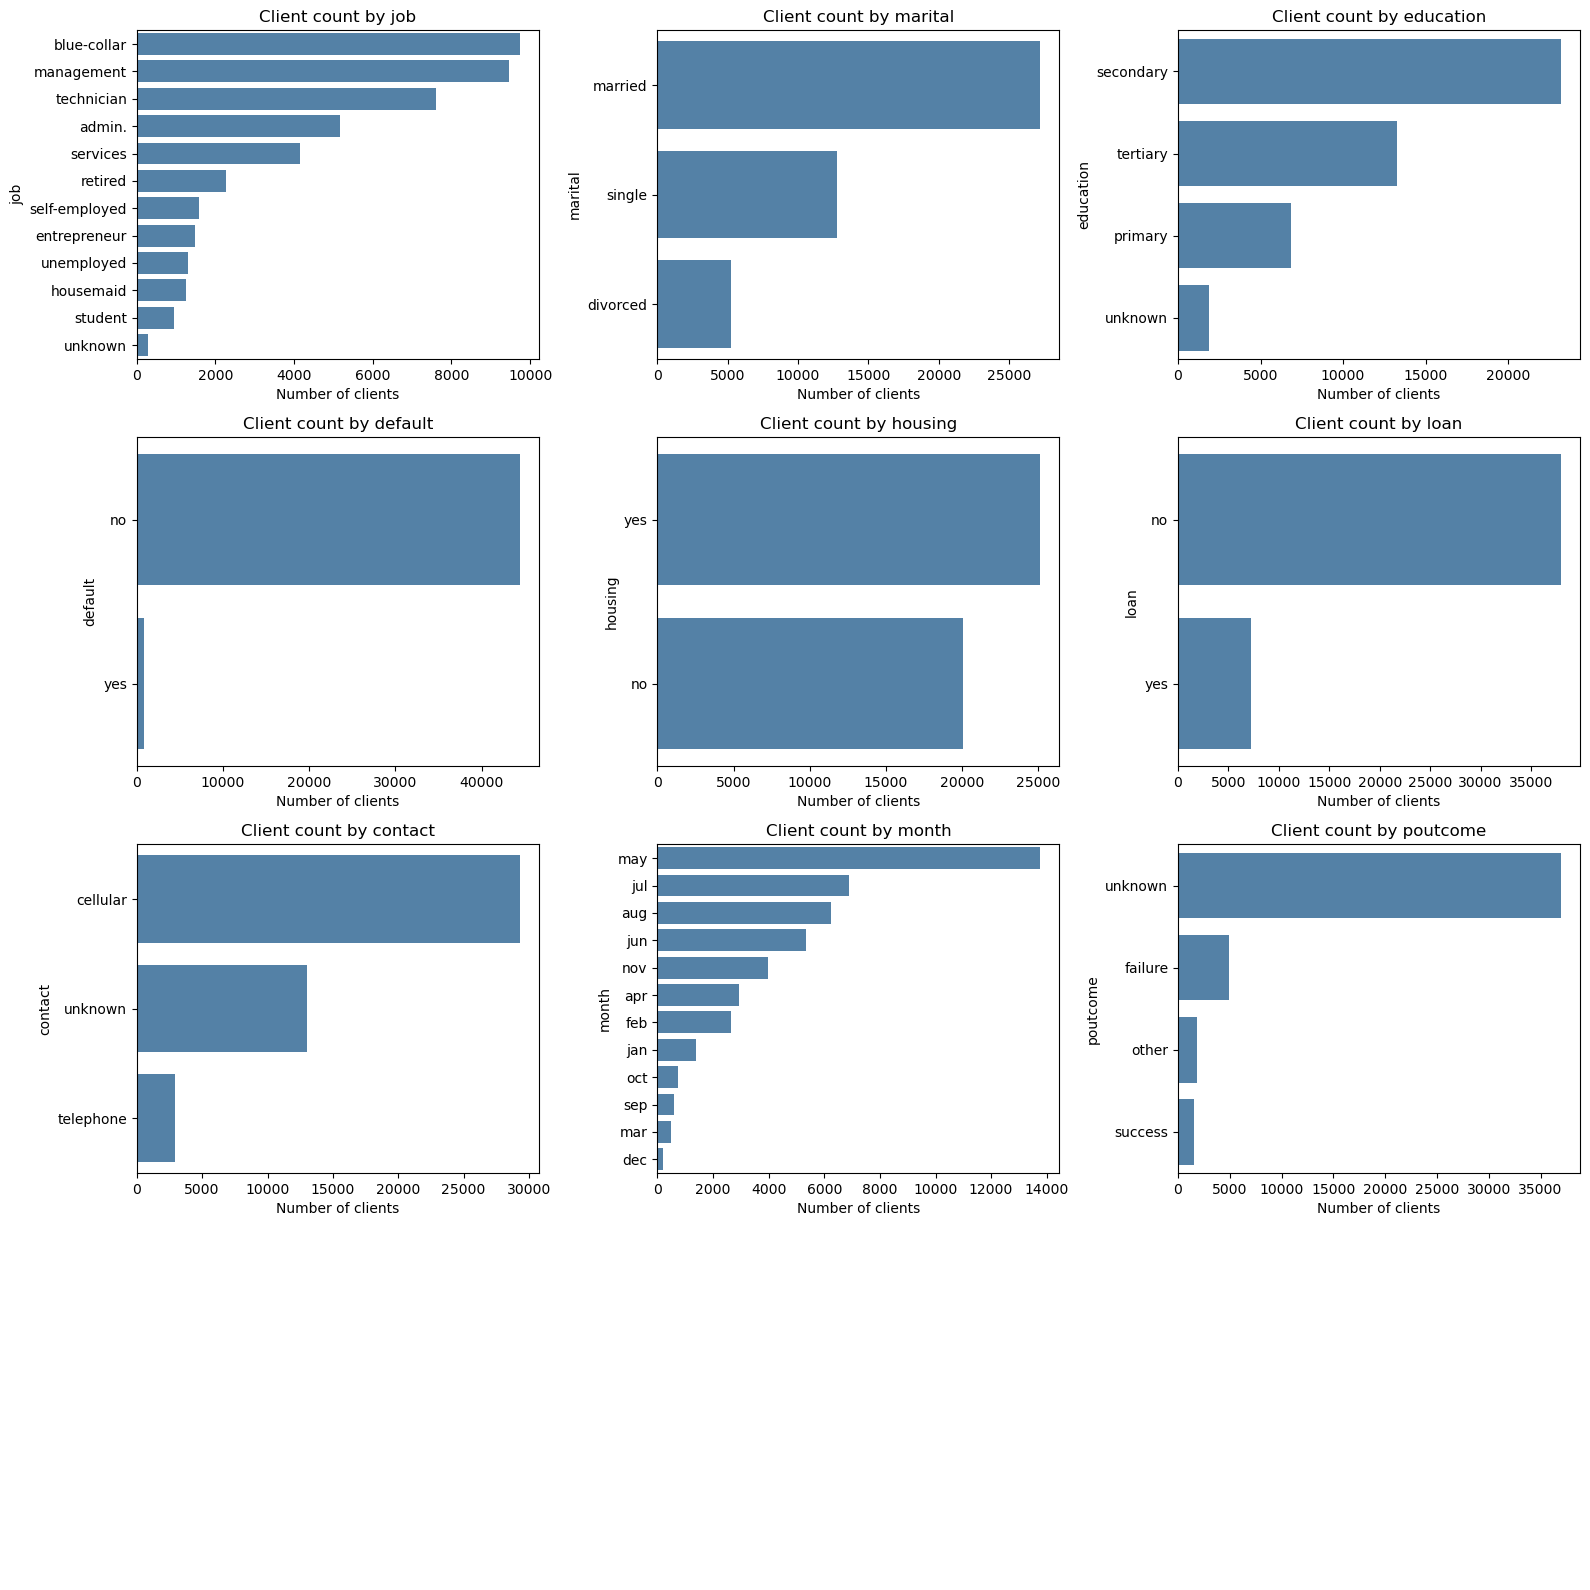

In [12]:
fig, axes = plt.subplots(4, 3, figsize=(16, 16))
for ax, col in zip(axes.flat, categorical_features_all):
    order = df[col].value_counts().index
    sns.countplot(data=df, y=col, order=order, ax=ax, color="steelblue")
    ax.set_title(f"Client count by {col}")
    ax.set_xlabel("Number of clients")
    ax.set_ylabel(col)
for ax in axes.flat[len(categorical_features_all):]:
    ax.axis("off")
plt.tight_layout()
plt.show()


These plots show which groups are common and which are rare. Rare categories matter because one-hot encoding can create columns with only a few examples; the train/test split will be stratified so the overall target ratio is preserved.

## Task 2.4 Compare key features with the target

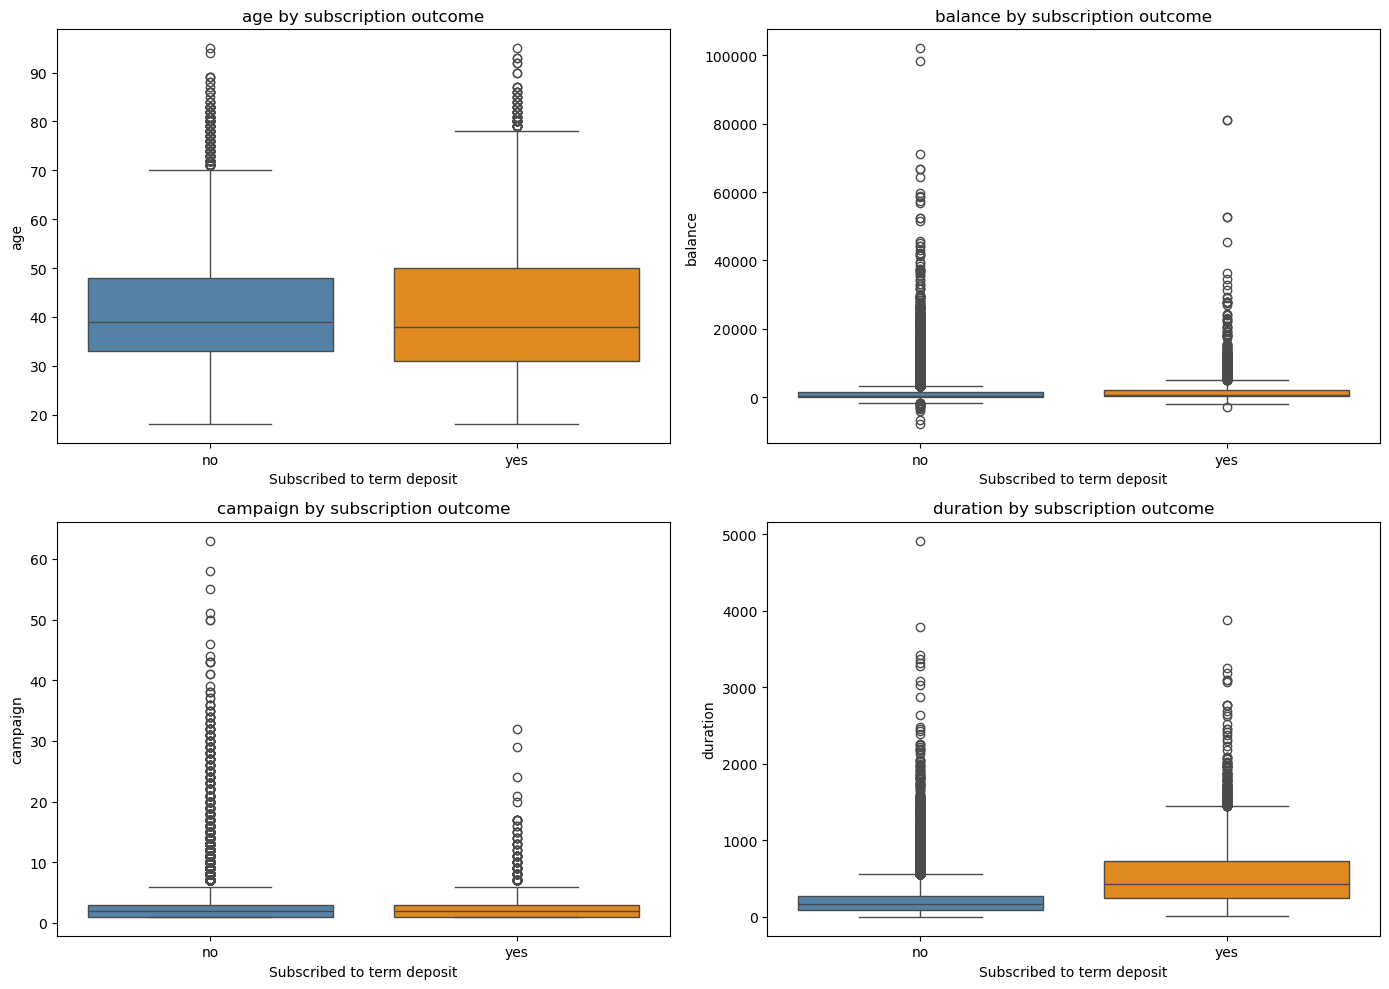

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, col in zip(axes.flat, ["age", "balance", "campaign", "duration"]):
    sns.boxplot(data=df, x="y", y=col, order=["no", "yes"], hue="y", legend=False, ax=ax, palette=["steelblue", "darkorange"])
    ax.set_title(f"{col} by subscription outcome")
    ax.set_xlabel("Subscribed to term deposit")
    ax.set_ylabel(col)
plt.tight_layout()
plt.show()


The boxplots compare the distributions of selected numeric features between subscribers and non-subscribers. Duration is included here for descriptive analysis only. If the goal is to select clients before calling them, duration cannot be an input because the future call has not happened yet.

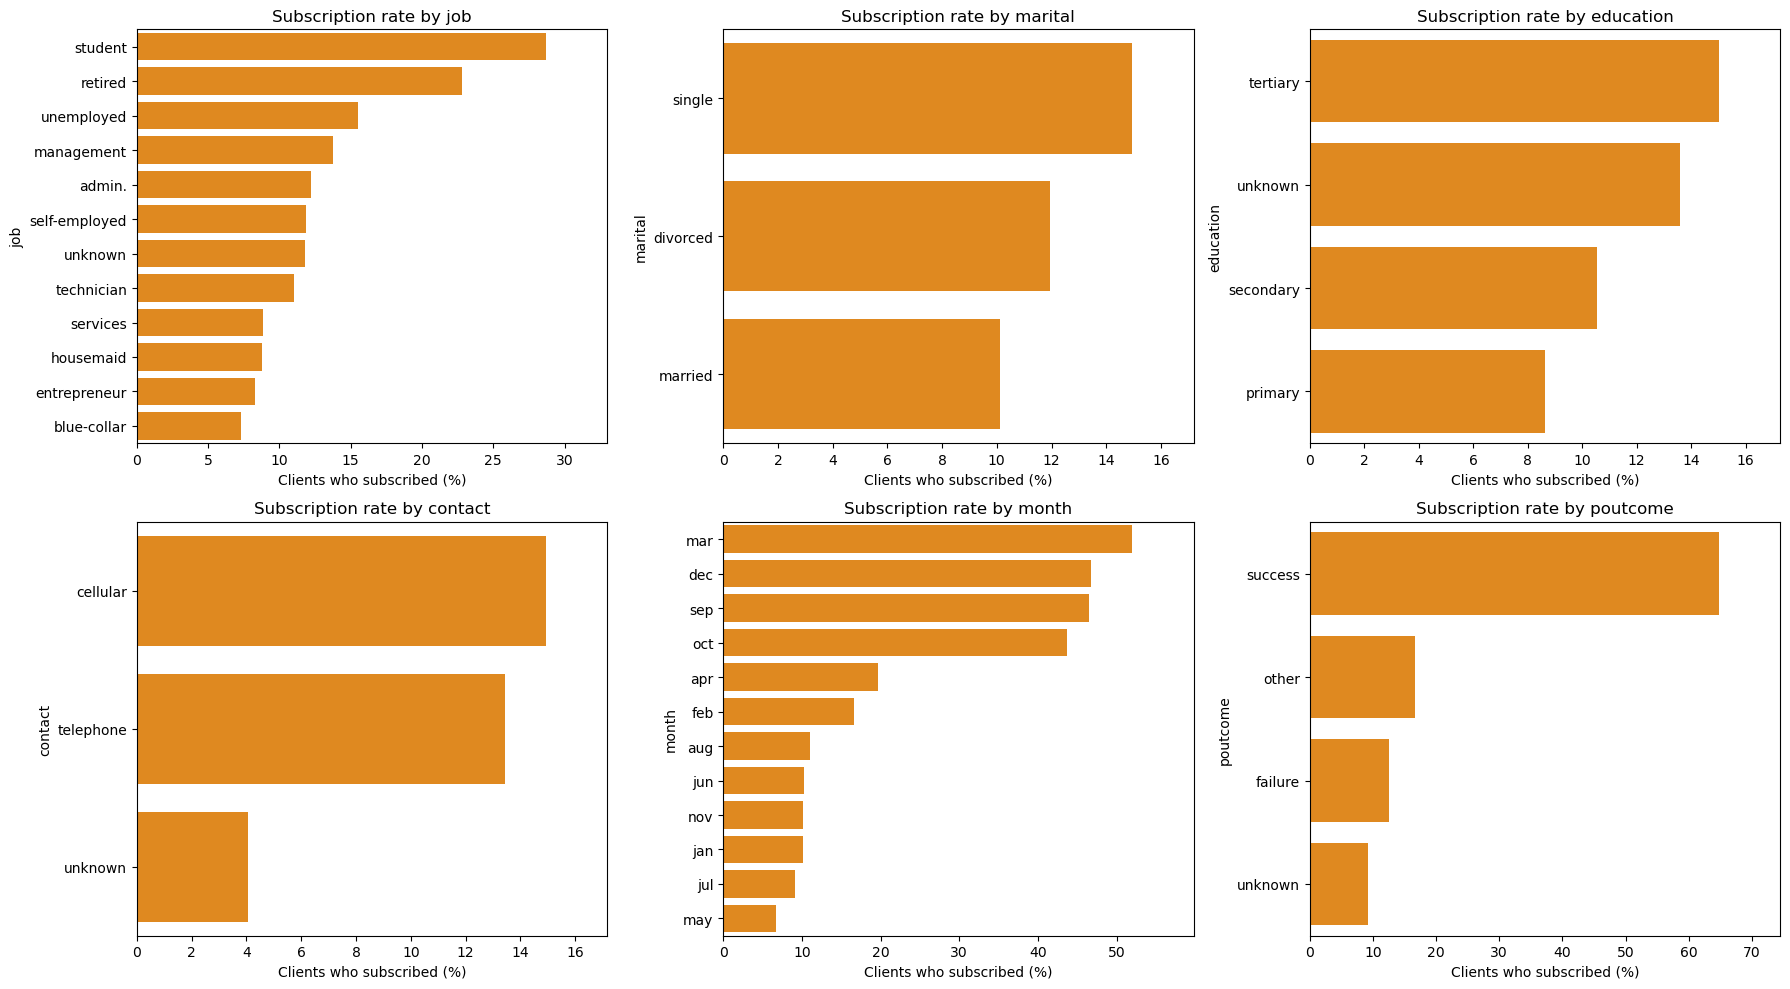

In [14]:
categorical_rate_features = ["job", "marital", "education", "contact", "month", "poutcome"]
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, col in zip(axes.flat, categorical_rate_features):
    rate = df.groupby(col, observed=True)["y"].apply(lambda s: (s == "yes").mean()).sort_values(ascending=False)
    sns.barplot(x=rate.values * 100, y=rate.index, ax=ax, color="darkorange")
    ax.set_title(f"Subscription rate by {col}")
    ax.set_xlabel("Clients who subscribed (%)")
    ax.set_ylabel(col)
    ax.set_xlim(0, max(5, (rate.max() * 100) * 1.15))
plt.tight_layout()
plt.show()


Subscription rates help compare group-level response, but they do not prove that a category causes subscription. The group sizes differ, and some high-rate groups may contain relatively few clients.

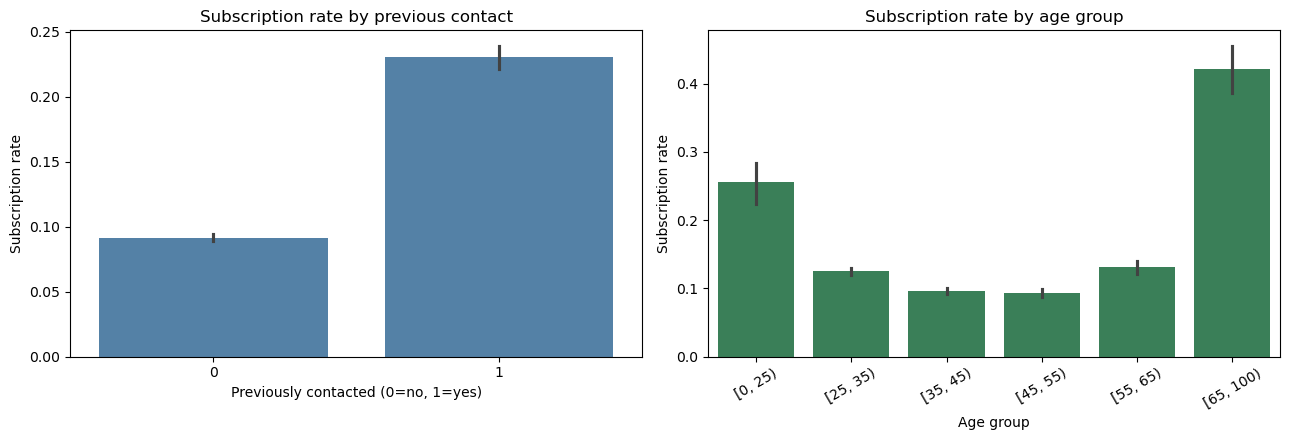

In [15]:
df_eda = df.assign(
    subscribed=target_numeric,
    previously_contacted=(df["pdays"] != -1).astype(int)
)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.barplot(data=df_eda, x="previously_contacted", y="subscribed", ax=axes[0], color="steelblue")
axes[0].set_title("Subscription rate by previous contact")
axes[0].set_xlabel("Previously contacted (0=no, 1=yes)")
axes[0].set_ylabel("Subscription rate")
df_eda["age_group"] = pd.cut(df_eda["age"], bins=[0, 25, 35, 45, 55, 65, 100], right=False)
sns.barplot(data=df_eda, x="age_group", y="subscribed", ax=axes[1], color="seagreen")
axes[1].set_title("Subscription rate by age group")
axes[1].set_xlabel("Age group")
axes[1].set_ylabel("Subscription rate")
axes[1].tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()


Clients contacted previously had a higher observed subscription rate (23.1%) than clients with no prior contact (9.2%). The 65+ age group also had a higher rate (42.1%), while age groups from 35 to 55 were around 9–10%. The youngest and oldest groups each contain fewer than 1,000 clients, so their rates are less stable. These are associations in this dataset, not evidence that prior contact or age causes a subscription.


## Task 2.5 Correlation between numeric variables

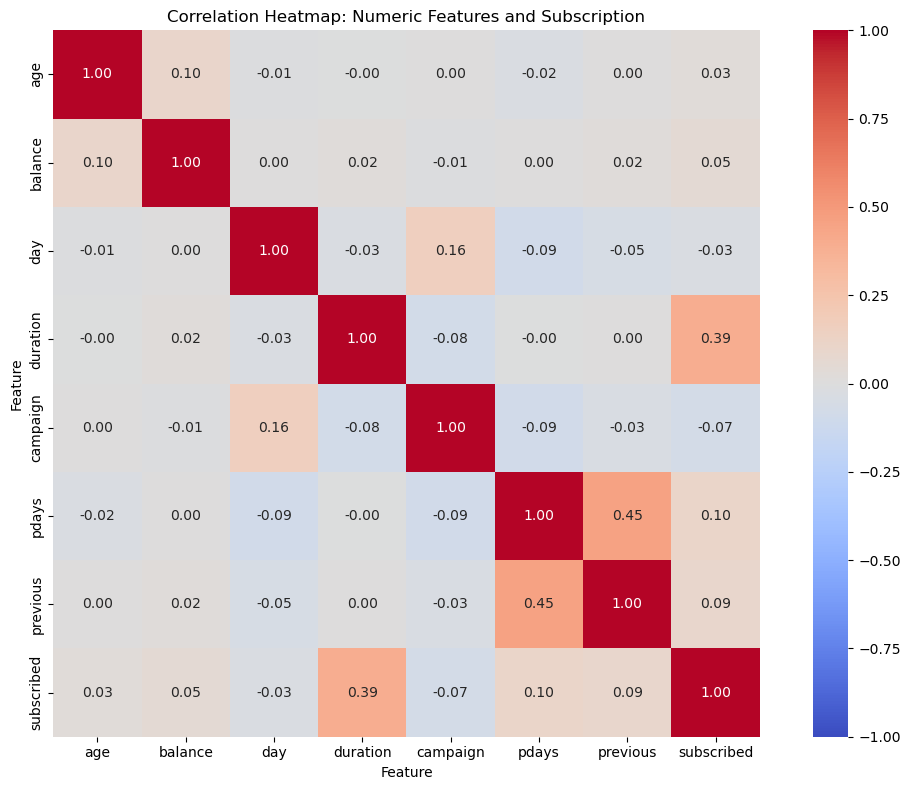

In [16]:
correlation_data = df[numeric_features_all].copy()
correlation_data["subscribed"] = target_numeric
corr_matrix = correlation_data.corr()

plt.figure(figsize=(11, 8))
sns.heatmap(corr_matrix, cmap="coolwarm", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f", square=True)
plt.title("Correlation Heatmap: Numeric Features and Subscription")
plt.xlabel("Feature")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


In [17]:
target_corr = corr_matrix["subscribed"].drop("subscribed").sort_values(key=lambda s: s.abs(), ascending=False)
target_corr.to_frame("Correlation with subscription").round(3)


,Correlation with subscription
duration,0.395
pdays,0.104
previous,0.093
campaign,-0.073
balance,0.053
day,-0.028
age,0.025


The heatmap summarizes linear relationships among numeric variables and the encoded target. Correlation can miss non-linear and categorical relationships, and it does not establish causation. Duration may show a strong association, but it remains excluded from the pre-call model because it leaks information from the call itself.

# 3) Preprocessing

## Task 3.1 Prepare features and target

In [18]:
# Add a feature with a direct business meaning for the pdays = -1 code.
model_df = df.copy()
model_df["previously_contacted"] = (model_df["pdays"] != -1).astype(int)

# Call duration is excluded because it is only available after the call.
excluded_features = ["y", "duration"]
X = model_df.drop(columns=excluded_features)
y = model_df["y"].map({"no": 0, "yes": 1})

numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

print(f"Positive class (subscribed=yes): {int(y.sum()):,} ({y.mean():.1%})")
print(f"Features used: {X.shape[1]}")
print(f"Numeric features ({len(numeric_features)}): {numeric_features}")
print(f"Categorical features ({len(categorical_features)}): {categorical_features}")


Positive class (subscribed=yes): 5,289 (11.7%)
Features used: 16
Numeric features (7): ['age', 'balance', 'day', 'campaign', 'pdays', 'previous', 'previously_contacted']
Categorical features (9): ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']


We convert the target to 0/1 so model metrics consistently treat subscription as the positive class. We also add a clear previous-contact indicator and exclude duration to keep predictions available before a call.

## Task 3.2 Split train/test

In [19]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print(f"Training rows: {len(X_train):,}")
print(f"Test rows: {len(X_test):,}")
print(f"Training subscription rate: {y_train.mean():.3%}")
print(f"Test subscription rate: {y_test.mean():.3%}")


Training rows: 36,168
Test rows: 9,043
Training subscription rate: 11.698%
Test subscription rate: 11.700%


The test set is held out until evaluation. Stratification keeps the rare subscription class at a similar proportion in training and test data.

## Task 3.3 Build a preprocessing pipeline

In [20]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), numeric_features),
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ],
    # The encoded dataset is small enough to keep dense for compatibility across models.
    sparse_threshold=0
)

print("Preprocessing steps: standardize numeric columns; one-hot encode categorical columns.")


Preprocessing steps: standardize numeric columns; one-hot encode categorical columns.


Numeric features are standardized so distance- and margin-based models such as KNN and SVM are not dominated by variables with large units. Categorical fields are one-hot encoded without imposing a false numeric order. The preprocessor is fitted inside each model pipeline on the training split only, which prevents test-set information from leaking into training.

# 4) Train Classification Models

## Task 4.1 Define model candidates

In [21]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1500, class_weight="balanced", random_state=RANDOM_STATE
    ),
    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced", min_samples_leaf=10, random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=250, class_weight="balanced_subsample",
        min_samples_leaf=2, n_jobs=-1, random_state=RANDOM_STATE
    ),
    "KNN": KNeighborsClassifier(n_neighbors=15, weights="distance", n_jobs=-1),
    "SVM (linear)": LinearSVC(
        class_weight="balanced", max_iter=5000, random_state=RANDOM_STATE
    )
}

boosting_name = "Gradient Boosting (scikit-learn fallback)"
try:
    from xgboost import XGBClassifier
    models["XGBoost"] = XGBClassifier(
        n_estimators=300, max_depth=4, learning_rate=0.05,
        subsample=0.85, colsample_bytree=0.85,
        scale_pos_weight=(y_train == 0).sum() / (y_train == 1).sum(),
        eval_metric="logloss", n_jobs=-1, random_state=RANDOM_STATE
    )
    boosting_name = "XGBoost"
except ImportError:
    from sklearn.ensemble import HistGradientBoostingClassifier
    models[boosting_name] = HistGradientBoostingClassifier(
        max_iter=250, learning_rate=0.08, max_leaf_nodes=20,
        class_weight="balanced", random_state=RANDOM_STATE
    )

print("Models to train:")
for name in models:
    print("-", name)


Models to train:
- Logistic Regression
- Decision Tree
- Random Forest
- KNN
- SVM (linear)
- Gradient Boosting (scikit-learn fallback)


We compare logistic regression, a decision tree, random forest, KNN, a linear SVM, and a boosting model. The code uses XGBoost when it is installed; otherwise it uses scikit-learn histogram gradient boosting so the notebook still runs in a standard scikit-learn environment.

Class weights are used where supported to make errors on the smaller subscription class matter more during fitting. This is one way to address imbalance; it does not replace careful evaluation.

## Task 4.2 Fit each pipeline

In [22]:
fitted_models = {}
for name, estimator in models.items():
    pipeline = Pipeline([
        ("preprocessing", preprocessor),
        ("model", estimator)
    ])
    pipeline.fit(X_train, y_train)
    fitted_models[name] = pipeline

print(f"Fitted {len(fitted_models)} models.")


Fitted 6 models.


Each candidate receives the same training and test partitions and the same preprocessing steps. This makes the comparison easier to interpret and ensures transformations are learned from training data only.

# 5) Evaluate Models

## Task 5.1 Calculate classification metrics

In [23]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix
)

def get_model_scores(model, X_values):
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X_values)[:, 1]
    return model.decision_function(X_values)

model_results = {}
score_values = {}
prediction_values = {}

for name, model in fitted_models.items():
    predictions = model.predict(X_test)
    scores = get_model_scores(model, X_test)
    prediction_values[name] = predictions
    score_values[name] = scores
    model_results[name] = {
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1": f1_score(y_test, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, scores),
        "PR-AUC (Average Precision)": average_precision_score(y_test, scores),
        "Confusion Matrix": confusion_matrix(y_test, predictions, labels=[0, 1])
    }

metrics_table = pd.DataFrame({
    name: {metric: value for metric, value in values.items() if metric != "Confusion Matrix"}
    for name, values in model_results.items()
}).T.sort_values("PR-AUC (Average Precision)", ascending=False)

metrics_table.round(3)


,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC (Average Precision)
Gradient Boosting (scikit-learn fallback),0.819,0.350,0.639,0.452,0.802,0.470
Random Forest,0.886,0.515,0.396,0.448,0.802,0.449
Logistic Regression,0.755,0.267,0.624,0.374,0.772,0.409
SVM (linear),0.758,0.268,0.619,0.374,0.772,0.405
KNN,0.893,0.649,0.187,0.291,0.738,0.380
Decision Tree,0.736,0.239,0.576,0.338,0.717,0.340


ROC-AUC measures how well the model ranks subscribers above non-subscribers across thresholds. PR-AUC (average precision) focuses on precision and recall for the positive class and is especially useful with an imbalanced target.

Precision tells us what fraction of clients predicted to subscribe actually subscribed. Recall tells us what fraction of all subscribers the model found. F1 balances precision and recall. Accuracy is included for context, but should not be used alone.

## Task 5.2 Compare confusion matrices

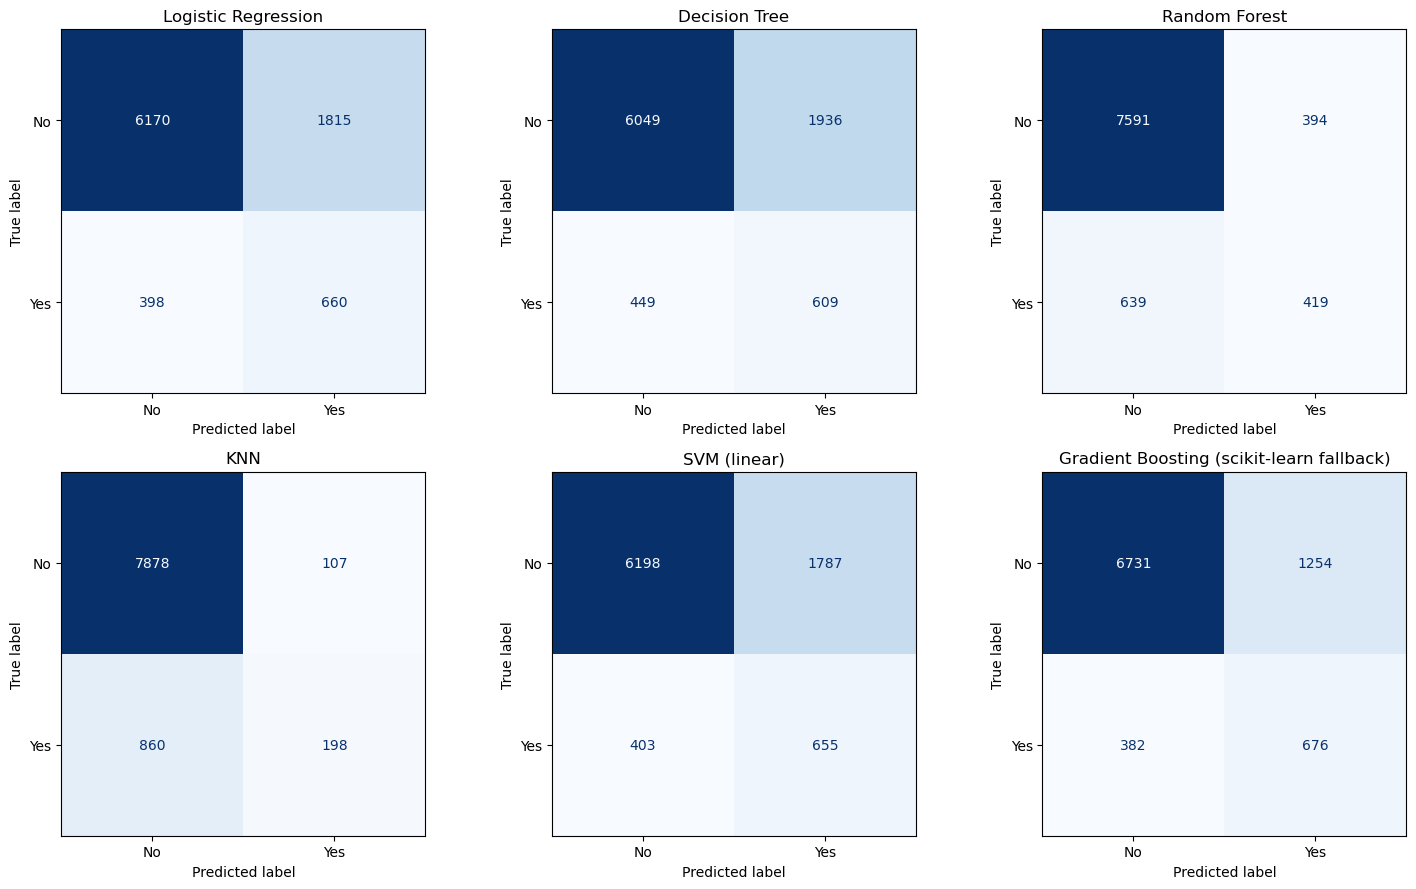

In [24]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, (name, predictions) in zip(axes.flat, prediction_values.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, predictions, labels=[0, 1],
        display_labels=["No", "Yes"], cmap="Blues",
        values_format="d", ax=ax, colorbar=False
    )
    ax.set_title(name)
for ax in axes.flat[len(prediction_values):]:
    ax.axis("off")
plt.tight_layout()
plt.show()


In each confusion matrix, the bottom-left cell is the number of subscribers missed by the model (false negatives), and the top-right cell is the number of non-subscribers incorrectly selected (false positives). The campaign owner should decide which error is more costly.

## Task 5.3 Plot ROC-AUC curves

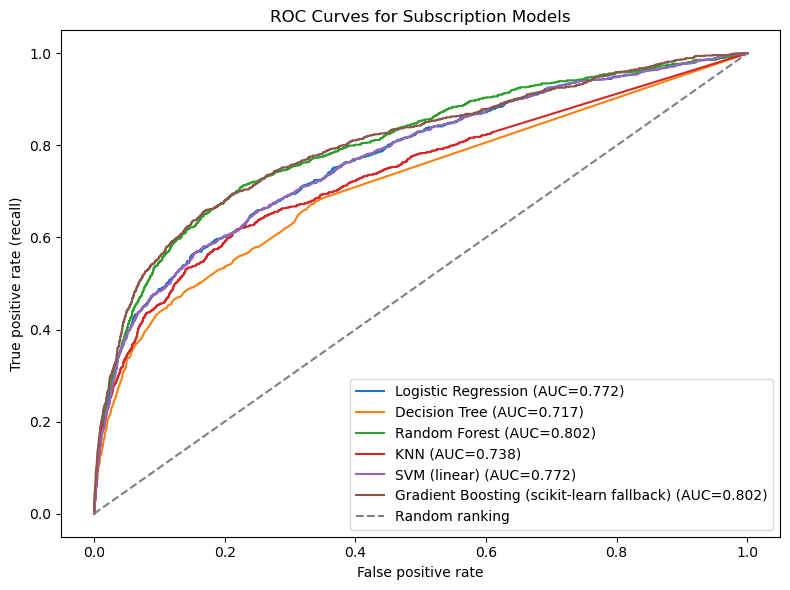

In [25]:
from sklearn.metrics import roc_curve

plt.figure(figsize=(8, 6))
for name, scores in score_values.items():
    fpr, tpr, _ = roc_curve(y_test, scores)
    auc_value = model_results[name]["ROC-AUC"]
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc_value:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random ranking")
plt.title("ROC Curves for Subscription Models")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate (recall)")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


The ROC curve shows the trade-off between finding subscribers and incorrectly flagging non-subscribers as the decision threshold changes. A curve closer to the top-left indicates stronger ranking performance.

## Task 5.4 Plot precision-recall curves

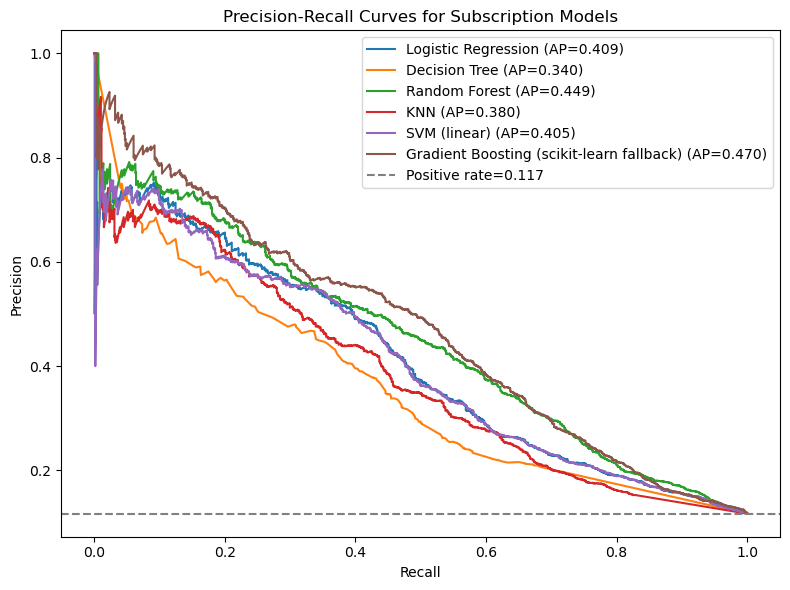

In [26]:
from sklearn.metrics import precision_recall_curve

plt.figure(figsize=(8, 6))
for name, scores in score_values.items():
    precision_values, recall_values, _ = precision_recall_curve(y_test, scores)
    ap_value = model_results[name]["PR-AUC (Average Precision)"]
    plt.plot(recall_values, precision_values, label=f"{name} (AP={ap_value:.3f})")
baseline_rate = y_test.mean()
plt.axhline(baseline_rate, linestyle="--", color="gray", label=f"Positive rate={baseline_rate:.3f}")
plt.title("Precision-Recall Curves for Subscription Models")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.legend(loc="best")
plt.tight_layout()
plt.show()


The dashed baseline equals the share of subscribers in the test set. A useful model should stay above that baseline across a meaningful part of the recall range. The precision-recall view makes the positive-class trade-off easier to see than accuracy.

# 6) Business Threshold and Campaign Capacity

## Task 6.1 Compare thresholds for the leading probability model

In [27]:
# Select the highest PR-AUC model that exposes predict_proba scores.
score_models = [
    name for name, model in fitted_models.items()
    if hasattr(model, "predict_proba")
]
best_score_model = max(
    score_models,
    key=lambda name: model_results[name]["PR-AUC (Average Precision)"]
)
best_score_pipeline = fitted_models[best_score_model]
yes_score = best_score_pipeline.predict_proba(X_test)[:, 1]

threshold_rows = []
for threshold in [0.20, 0.35, 0.50, 0.65]:
    threshold_predictions = (yes_score >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, threshold_predictions, labels=[0, 1]).ravel()
    threshold_rows.append({
        "Threshold": threshold,
        "Precision": precision_score(y_test, threshold_predictions, zero_division=0),
        "Recall": recall_score(y_test, threshold_predictions, zero_division=0),
        "F1": f1_score(y_test, threshold_predictions, zero_division=0),
        "Selected for campaign": int(threshold_predictions.sum()),
        "Subscribers missed": int(fn),
        "Non-subscribers selected": int(fp)
    })

threshold_table = pd.DataFrame(threshold_rows).set_index("Threshold")
print(f"Model used for score-threshold comparison: {best_score_model}")
threshold_table.round(3)


Model used for score-threshold comparison: Gradient Boosting (scikit-learn fallback)


,Precision,Recall,F1,Selected for campaign,Subscribers missed,Non-subscribers selected
Threshold,,,,,,
0.20,0.138,0.954,0.241,7306,49,6297
0.35,0.217,0.801,0.341,3907,211,3060
0.50,0.350,0.639,0.452,1930,382,1254
0.65,0.471,0.522,0.495,1171,506,619


The threshold controls how many clients are selected for outreach. A lower cutoff usually finds more subscribers (higher recall) but also selects more non-subscribers. A higher cutoff tends to produce a smaller, more precise contact list.

These values are the class-weighted model’s predict_proba scores; they have not been checked for calibration, so interpret them as ranking scores rather than guaranteed real-world subscription probabilities. The table is calculated on the test set for illustration, which makes its measured performance optimistic after threshold exploration. For a final decision, choose the cutoff on a validation set, then evaluate it once on an untouched test set.

## Task 6.2 Create a review/priority queue

In [28]:
decision_zone = np.select(
    [yes_score < 0.20, yes_score < 0.50],
    ["Low priority", "Review / medium priority"],
    default="High priority"
)
zone_order = ["Low priority", "Review / medium priority", "High priority"]
zone_summary = pd.DataFrame({
    "Decision zone": decision_zone,
    "Actual subscribed": y_test.to_numpy()
}).groupby("Decision zone", observed=True).agg(
    Clients=("Actual subscribed", "size"),
    Actual_subscribers=("Actual subscribed", "sum"),
    Observed_subscription_rate=("Actual subscribed", "mean")
).reindex(zone_order)
zone_summary["Observed_subscription_rate"] = zone_summary["Observed_subscription_rate"].map(lambda value: f"{value:.1%}" if pd.notna(value) else "n/a")
zone_summary


,Clients,Actual_subscribers,Observed_subscription_rate
Decision zone,,,
Low priority,1737,49,2.8%
Review / medium priority,5376,333,6.2%
High priority,1930,676,35.0%


A priority queue lets the campaign team spend limited calling time on clients with higher model scores. The observed subscription rates in each zone describe this test sample; they are not guarantees for future campaigns, and the model scores have not been calibrated.

# 7) Business Demonstration and Summary

## Task 7.1 Compare model results

In [29]:
comparison = metrics_table.copy()
comparison["Comment"] = [
    "Strongest positive-class ranking in this test comparison." if name == metrics_table.index[0]
    else "Baseline comparison; check precision and recall against campaign capacity."
    for name in comparison.index
]
comparison.round(3)


,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC (Average Precision),Comment
Gradient Boosting (scikit-learn fallback),0.819,0.350,0.639,0.452,0.802,0.470,Strongest positive-class ranking in this test ...
Random Forest,0.886,0.515,0.396,0.448,0.802,0.449,Baseline comparison; check precision and recal...
Logistic Regression,0.755,0.267,0.624,0.374,0.772,0.409,Baseline comparison; check precision and recal...
SVM (linear),0.758,0.268,0.619,0.374,0.772,0.405,Baseline comparison; check precision and recal...
KNN,0.893,0.649,0.187,0.291,0.738,0.380,Baseline comparison; check precision and recal...
Decision Tree,0.736,0.239,0.576,0.338,0.717,0.340,Baseline comparison; check precision and recal...


The highest PR-AUC model is a useful candidate when the campaign needs a strong positive-class ranking, but it is not automatically the best operational choice. Review recall, precision, the confusion matrix, and the number of clients selected at a practical threshold.

## Task 7.2 Show example clients for the campaign

In [30]:
example_rows = X_test.copy()
example_rows["Actual subscription"] = y_test
example_rows["Model subscription score"] = yes_score
example_rows["Decision zone"] = decision_zone
example_rows = example_rows.sort_values("Model subscription score", ascending=False)

example_rows[[
    "age", "job", "marital", "education", "balance", "contact",
    "month", "campaign", "previously_contacted",
    "Actual subscription", "Model subscription score", "Decision zone"
]].head(10).style.format({"Model subscription score": "{:.1%}"})


,age,job,marital,education,balance,contact,month,campaign,previously_contacted,Actual subscription,Model subscription score,Decision zone
43123,48,housemaid,married,tertiary,5473,cellular,feb,2,1,1,97.6%,High priority
43122,20,student,single,secondary,215,cellular,feb,1,1,1,97.6%,High priority
43015,29,technician,single,secondary,113,cellular,feb,2,1,1,97.2%,High priority
43013,36,technician,married,tertiary,341,cellular,feb,2,1,1,97.1%,High priority
43165,28,student,single,secondary,1925,cellular,feb,1,1,0,96.8%,High priority
43164,30,management,single,tertiary,5359,cellular,feb,1,1,1,96.8%,High priority
45188,29,management,single,secondary,703,cellular,nov,1,1,1,96.8%,High priority
43005,60,retired,married,secondary,523,cellular,feb,1,1,1,96.7%,High priority
43135,25,student,single,secondary,469,cellular,feb,1,1,0,96.6%,High priority
45177,36,admin.,divorced,secondary,1224,cellular,nov,1,1,1,96.5%,High priority


These rows demonstrate how a campaign list can be sorted by the model score. The score supports staff prioritization; it is not a calibrated estimate or a guarantee for an individual client.

## Task 7.3 Final business interpretation

### Summary

- The dataset contains 45,211 client records. The target is whether a client subscribed to a term deposit; 11.7% of records are positive.
- The EDA compared class balance, numeric distributions, categorical counts, target rates by selected features, and correlations. It found no missing values or exact duplicate rows.
- The modeling pipeline standardized numeric fields and one-hot encoded categorical fields, fitting preprocessing on training data only.
- In this run, the scikit-learn Gradient Boosting fallback had the highest PR-AUC (0.470) and showed the highest ROC-AUC rounded to 0.802 (the same rounded value as Random Forest). At the default 0.50 cutoff it had precision 0.350, recall 0.639, and F1 0.452. Random Forest had similar F1 (0.448); KNN had the highest accuracy (0.893) but found only 18.7% of subscribers.
- Call duration was excluded because it is only known after the campaign call. Including it would make a pre-call model unrealistic and leak information about the outcome.
- Threshold results above were explored on the test set and should not be presented as an unbiased final estimate. Choose campaign capacity and error trade-offs on validation data, then evaluate the selected policy once on a fresh test set. Check score calibration before treating scores as actual subscription probabilities.

For this run, Gradient Boosting is the strongest ranking candidate by PR-AUC, but it does not dominate every metric. The campaign team should weigh its subscriber recall against the number of non-subscribers it would also contact.